In [1]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.append("C:/Users/admin/Desktop/JuliaDQMC/code/")
from DP_Lib import *

In [ ]:
import scienceplots
plt.style.use(['science','ieee'])

plt.rcParams.update({
    "legend.fancybox": True,
    "legend.frameon": True,
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Times"], #注意这里是Times，不是Times New Roman
    "font.size":6})

In [5]:
path="./"
dataC=pd.read_csv(os.path.join(path, "neq-eqC_H0.csv"),index_col=0)

In [11]:
LL=dataC.index.values.astype(int)
ECeq=dataC.values.astype(float).reshape(-1)

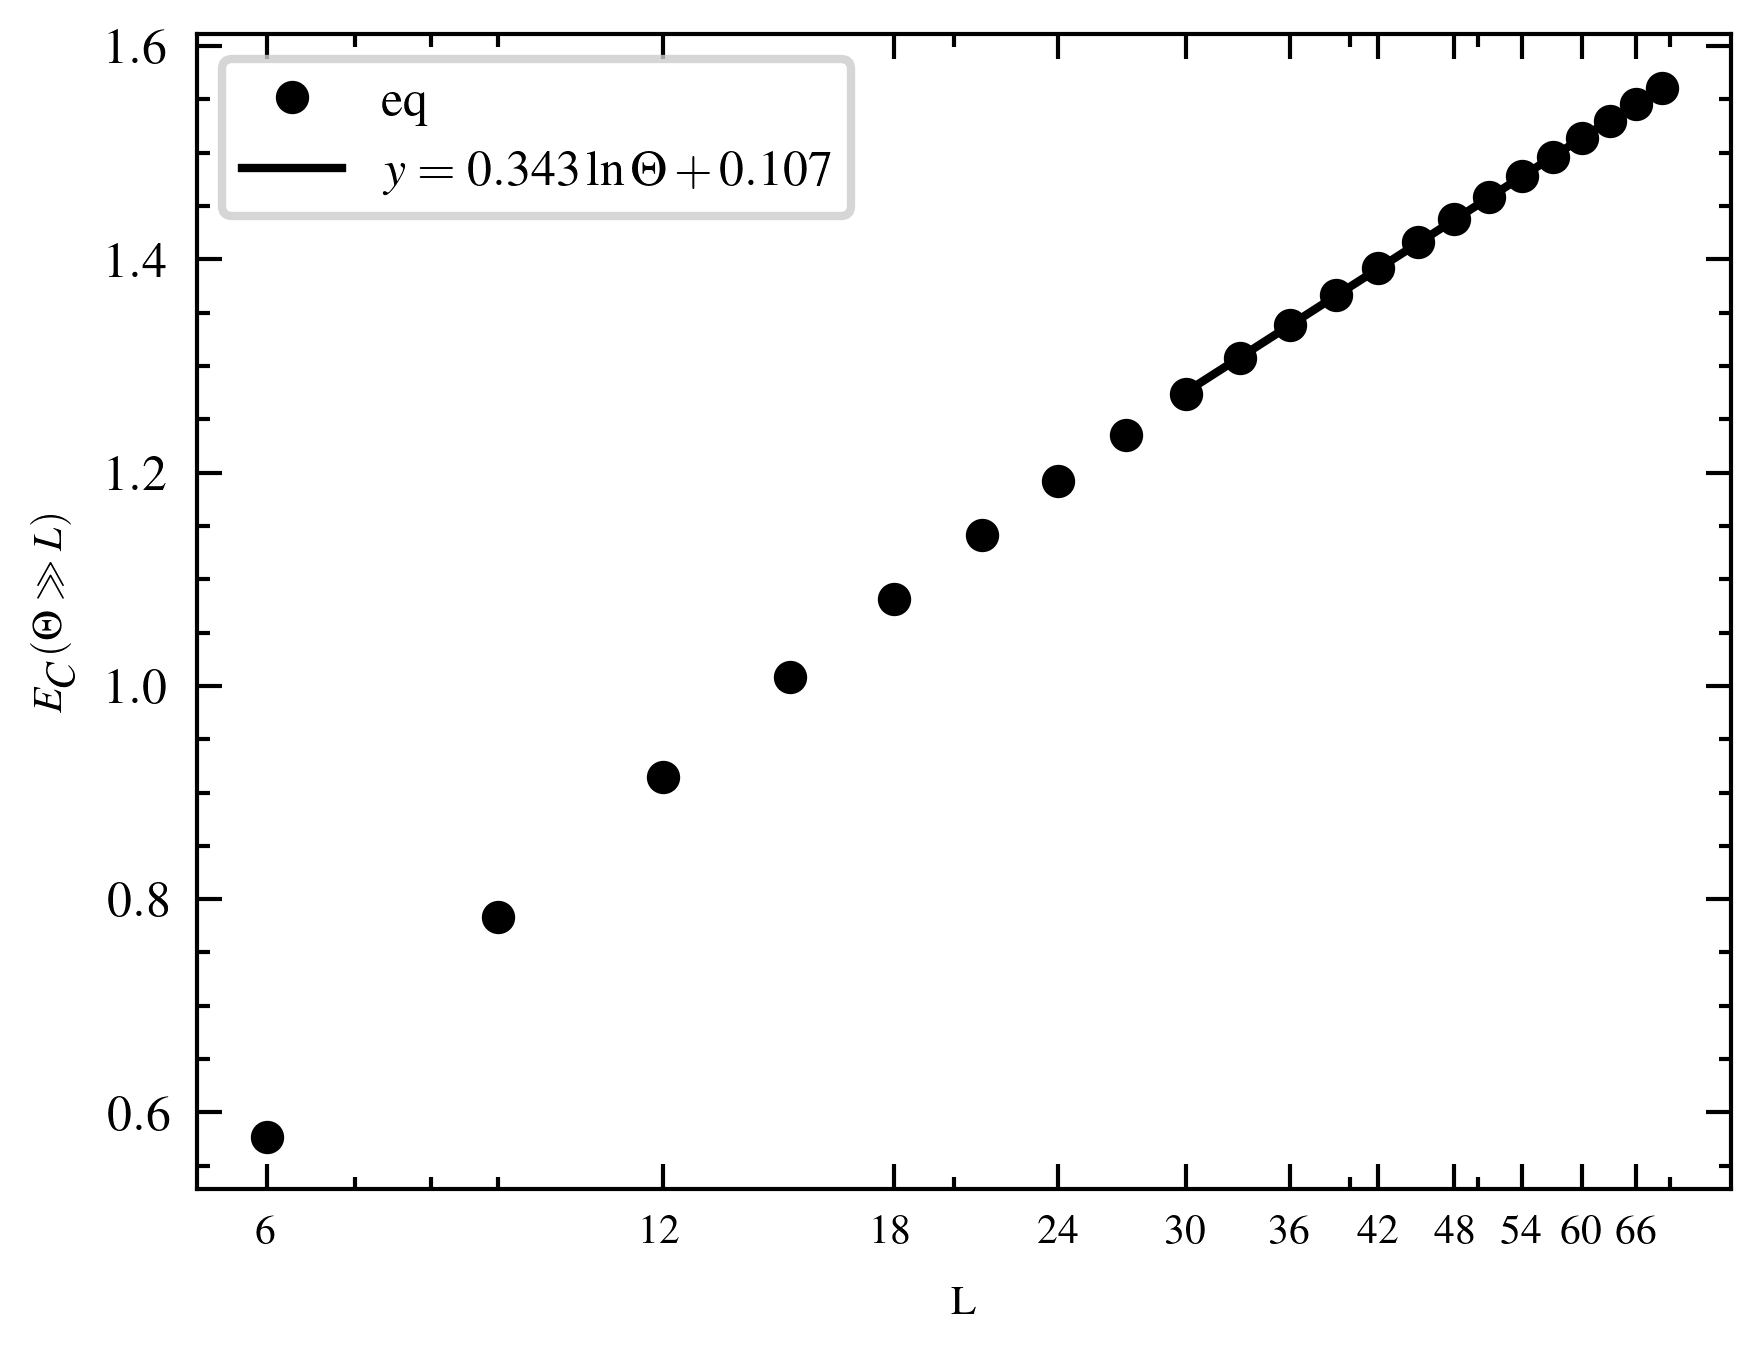

In [13]:
plt.plot(LL,ECeq,'o',label='eq',markersize=3,color='black')

xidx1=8
para,ds=linear_fit(np.log(LL[xidx1:]),ECeq[xidx1:])
x=np.linspace(LL[xidx1],LL[-1],100)
y=para[0]*np.log(x)+para[1]
plt.plot(x,y,label=f'$ y= {para[0]:.3f} \ln \Theta + {para[1]:.3f}$')

plt.legend()
plt.xscale('log')

plt.xticks(LL[::2],LL[::2],fontsize=5)
plt.xlabel('L',fontsize=5)
plt.ylabel(r'$E_C(\Theta\gg L)$',fontsize=5)
plt.show()

In [14]:
def EEfit_F(x, y, fix, arg):
    if fix == 0:
        A=np.ones((len(x),3))
        A[:,0]=x
        A[:,1]=np.log(x)
        return np.linalg.inv(A.transpose() @A)@A.transpose()@y
    
    elif fix == 1:
        y_adj = y - arg * x
        A=np.ones((len(x),2))
        A[:,0]=np.log(x)
        return np.linalg.inv(A.transpose() @A)@A.transpose()@y_adj
    
    elif fix == 2:
        y_adj = y - arg * np.log(x)
        A=np.ones((len(x),2))
        A[:,0]=x
        return np.linalg.inv(A.transpose() @A)@A.transpose()@y_adj


11


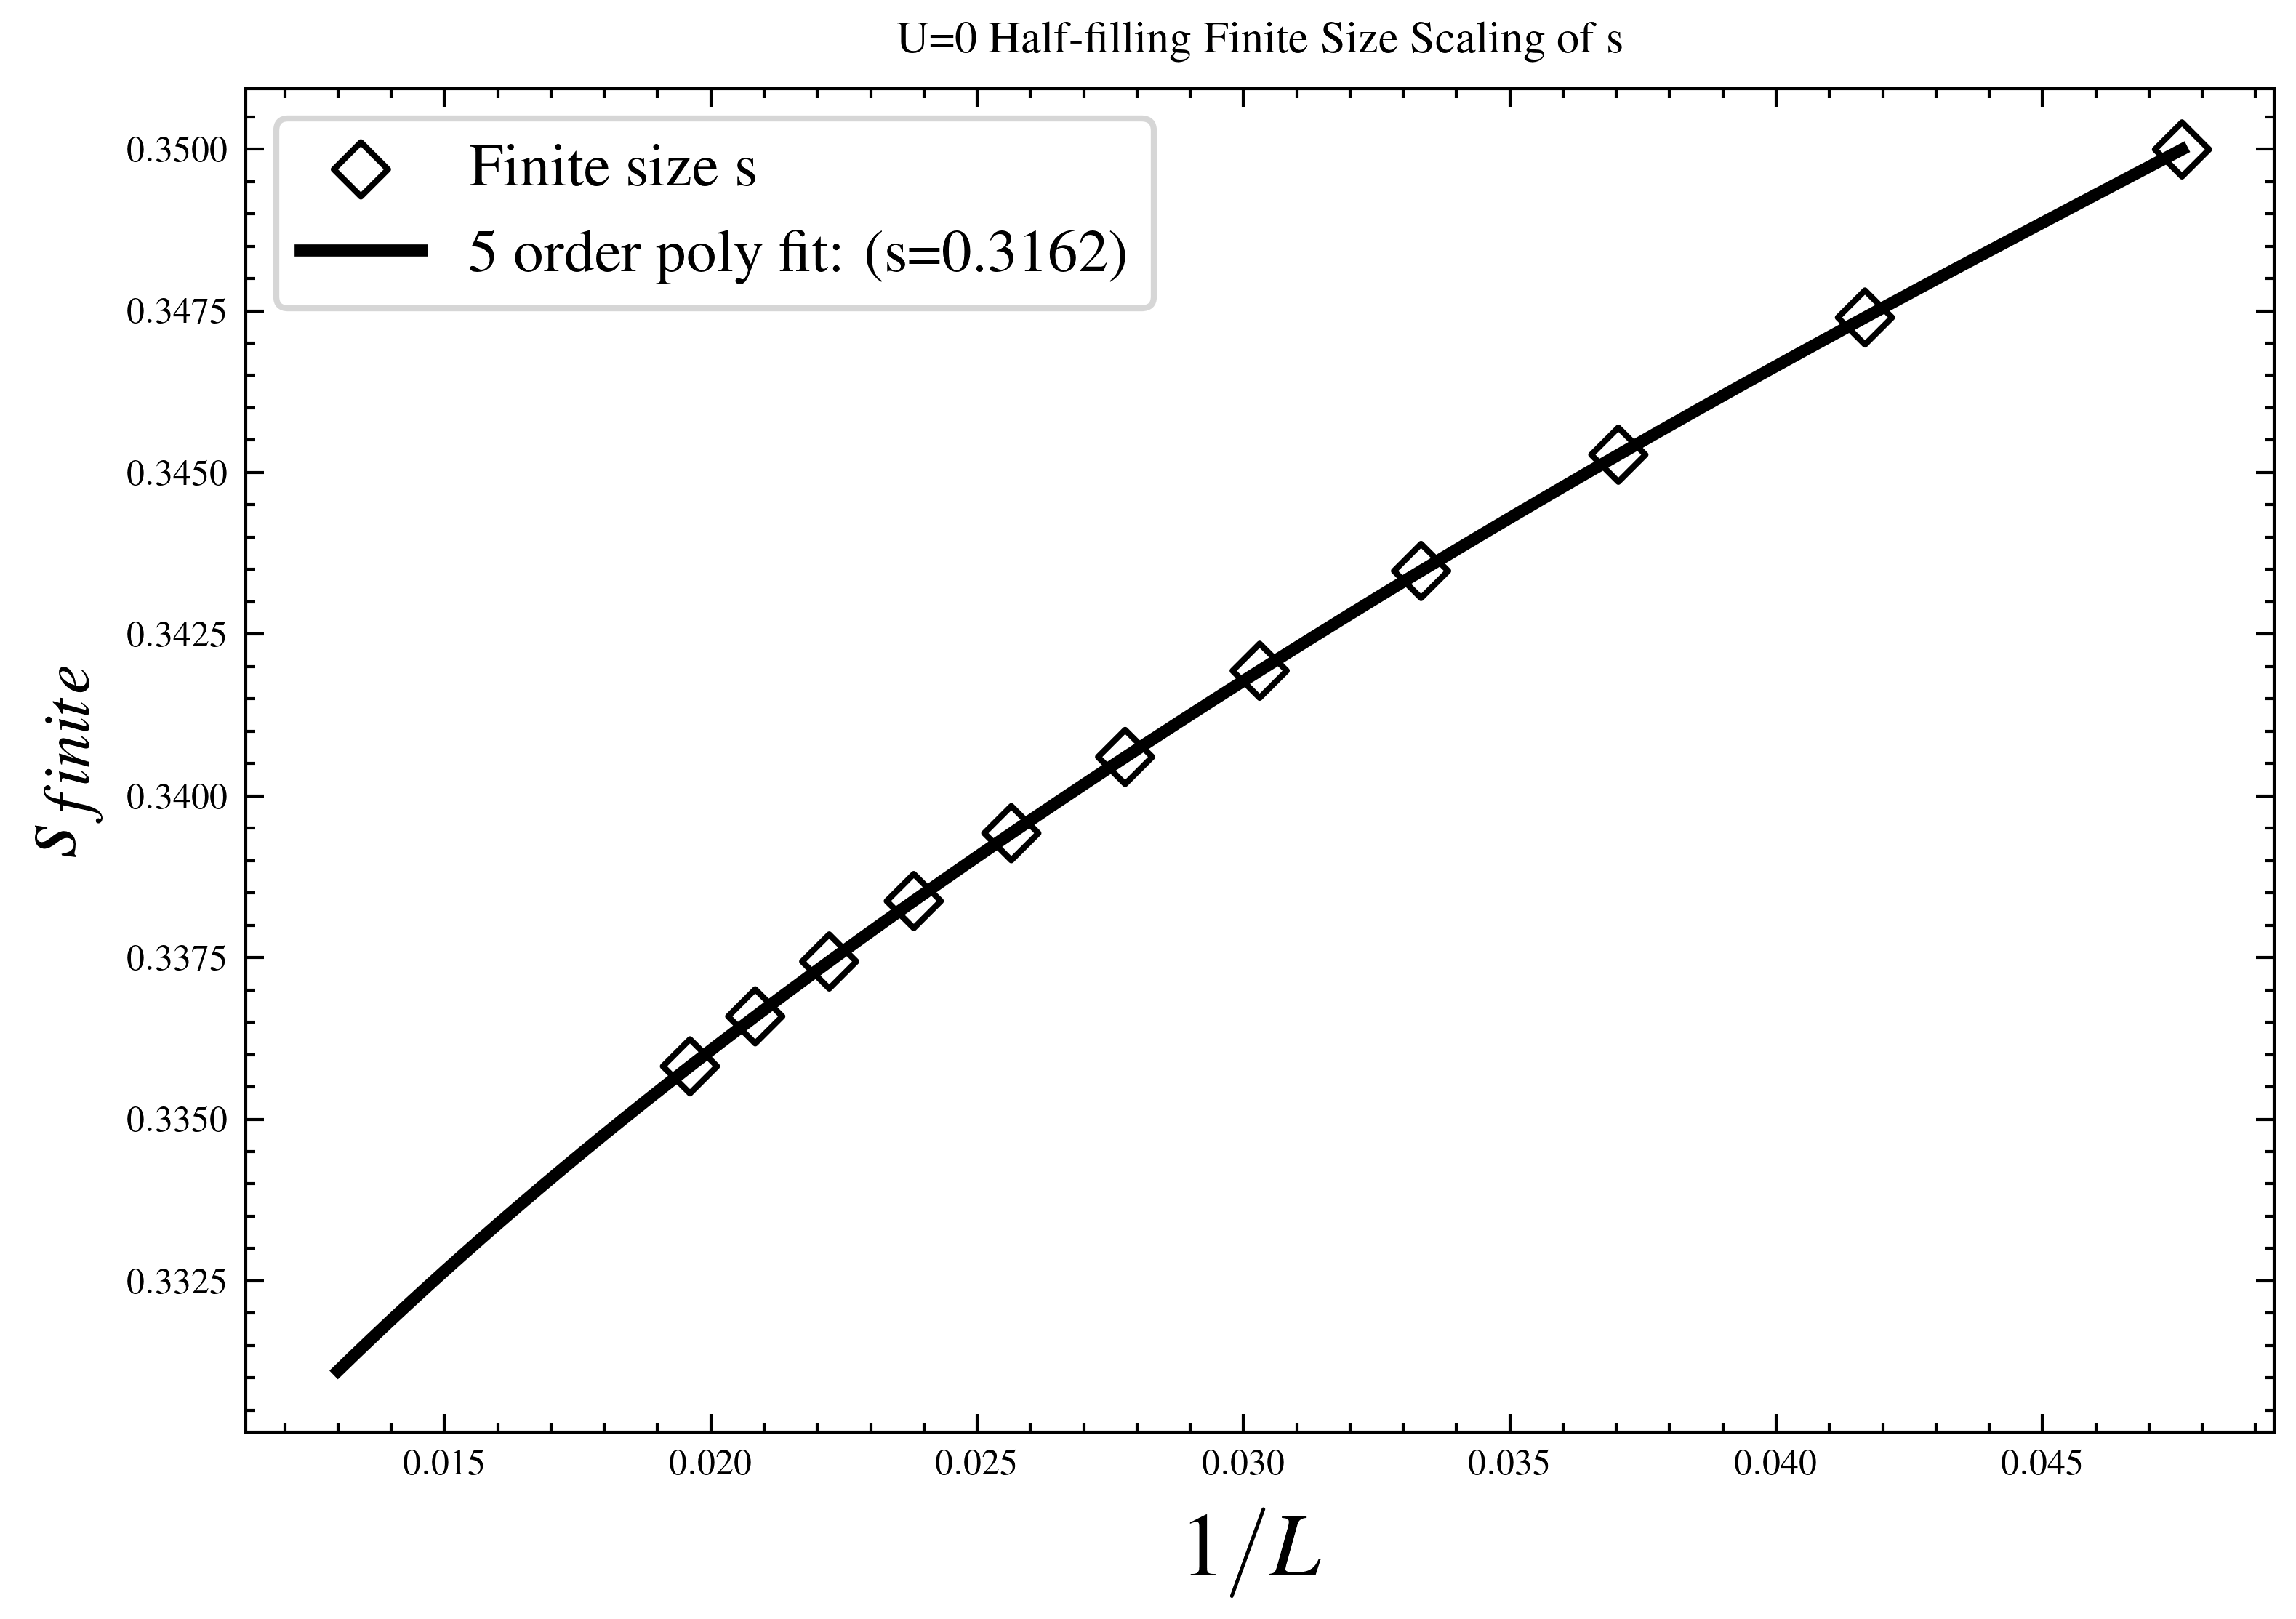

In [95]:
L_log=[]
para_log=[]
for xidx1 in range(5,len(ECeq)-6):
    # params=EEfit_F(LL[xidx1:], ECeq[xidx1:], 0, 0)
    # para_log.append(params[1])
    para,ds=linear_fit(np.log(LL[xidx1:]),ECeq[xidx1:])
    para_log.append(para[0])
    L_log.append(LL[xidx1])
print(len(para_log))
plt.figure(figsize=(6,4))
plt.scatter(1/np.array(L_log),para_log,marker='D',s=40,label="Finite size s", facecolors='none',edgecolors='black')
plt.xlabel(r'$1/L$',fontsize=15)
plt.ylabel(r'$s_{finite}$',fontsize=15)
plt.title('U=0 Half-filling Finite Size Scaling of s')

x_fit = np.linspace(0.013, max(1/np.array(L_log)), 1000)

# coeffs=powerfit(1/np.array(L_log), para_log)
# y_fit = coeffs[0]+coeffs[1]*(x_fit**coeffs[2]) 
# plt.plot(x_fit, y_fit, lw=2, 
#              label=f"Power fit: {coeffs[0]:.4f}+{coeffs[1]:.4f}*x\\^{coeffs[2]:.4f}  (s={coeffs[0]:.4f})")

for Nfit in [5]:
    coeffs = np.polyfit(1/np.array(L_log), para_log, Nfit)
    y_fit = np.polyval(coeffs, x_fit)
    plt.plot(x_fit, y_fit, lw=2, 
             label=f"{Nfit} order poly fit: (s={coeffs[-1]:.4f})")

plt.legend(fontsize=10)
plt.show()

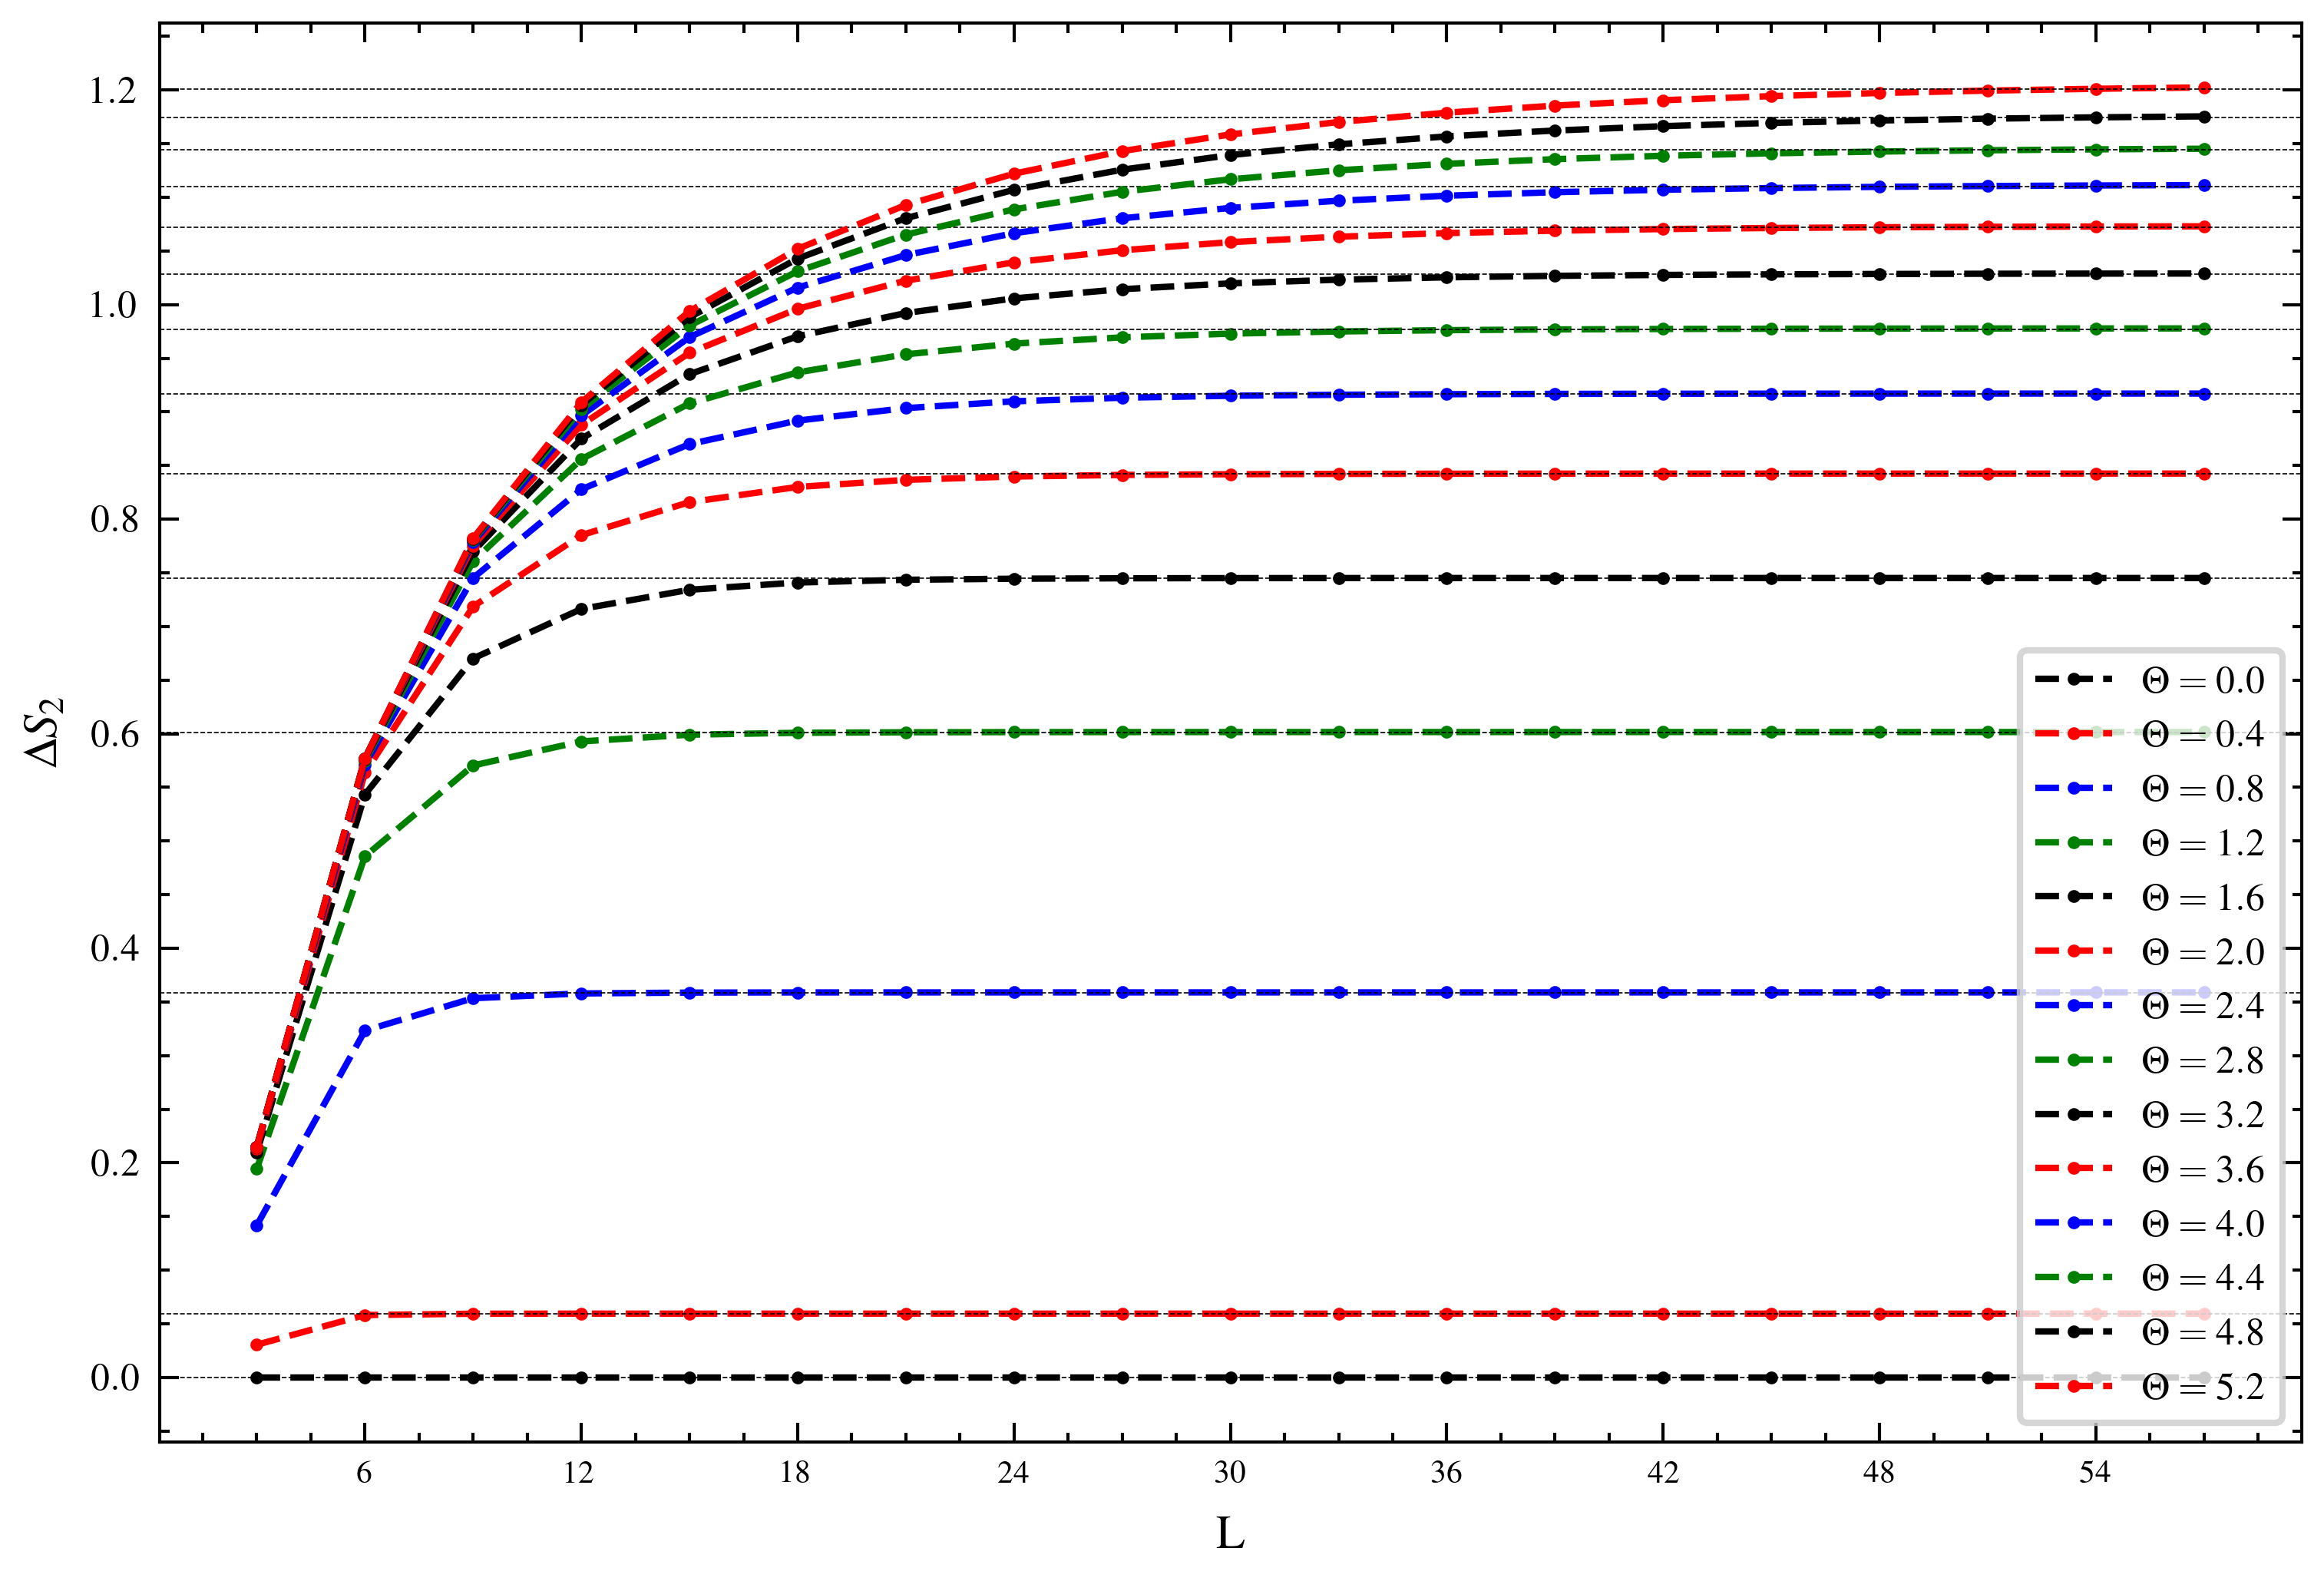

In [146]:
plt.figure(figsize=(6,4))

Theta=[]
ECneq=[]

for j in range(dataC.shape[1]):

    data=[(dataC.index[i],dataC.iloc[i,j],1e-3) for i in range(dataC.shape[0]) if np.isnan(dataC.iloc[i,j])==False ]
    index=unit_neardata(data)
    if len(index)>2:
        Theta.append(round(j*0.4,1))
        # print(Theta[-1])
        ECneq.append(np.mean(dataC.iloc[index,j]))
        data=np.array(data)
        plt.plot(data[:,0],data[:,1],linestyle='--',marker='o', markersize=1,label=f'$\\Theta={Theta[-1]:.1f}$')
        plt.axhline(ECneq[-1], color="black", linestyle='--',linewidth=0.2)

plt.rcParams.update({
    "legend.fancybox": True,
    "legend.frameon": True})

plt.legend()
plt.xlabel('L')
plt.ylabel(r'$\Delta S_2$')
# plt.title('U=0 Half-filling Nonequilibrium EC vs L')
# plt.ylim(-0.05,1.5)
plt.xticks(LL[::2],LL[::2],fontsize=5)
plt.show()



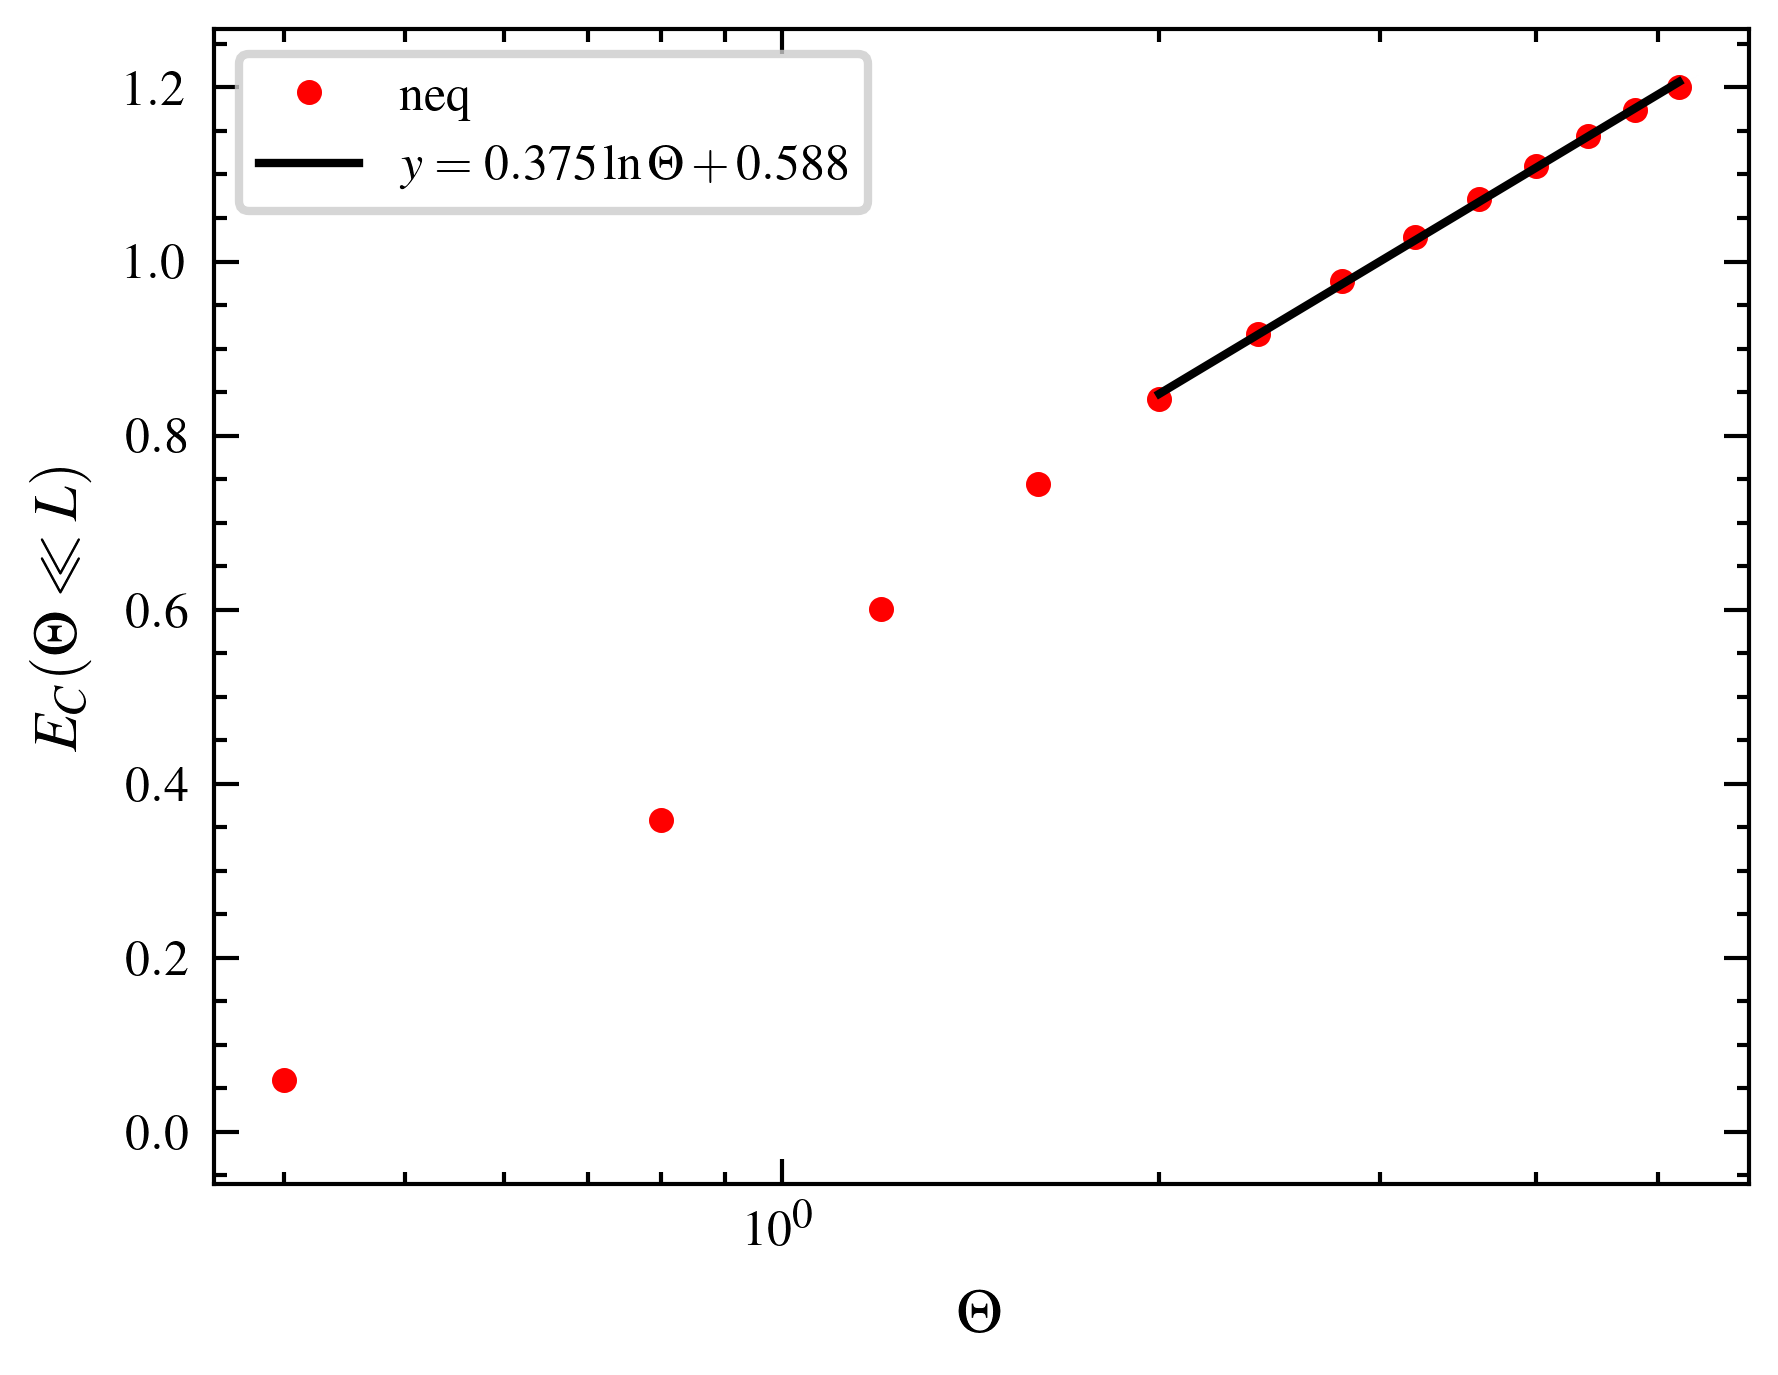

In [147]:
plt.plot(Theta,ECneq,'o',label='neq',markersize=2,color='red')

xidx1=5
para,ds=linear_fit(np.log(Theta[xidx1:]),ECneq[xidx1:])
x=np.linspace(Theta[xidx1],Theta[-1],100)
y=para[0]*np.log(x)+para[1]
plt.plot(x,y,label=f'$ y= {para[0]:.3f} \ln \Theta + {para[1]:.3f}$')

plt.xscale('log')
plt.xlabel(r'$\Theta$')
plt.ylabel(r'$E_C(\Theta\ll L)$')
plt.legend()
plt.show()

In [2]:
path="./"

dataA=pd.read_csv(os.path.join(path, "neqU0EE_Half - 副本.csv"),index_col=0)
dataB=pd.read_csv(os.path.join(path, "neqU0EE_HalfHalf - 副本.csv"),index_col=0)

dataSC=dataA.values-dataB
dataSC.to_csv(os.path.join(path, f"neqU0EE_SC - 副本.csv"))
LMAX=int(np.max(dataA.index))

In [3]:
dataSC=pd.read_csv(os.path.join(path, f"neqU0EE_SC.csv"),index_col=0)

NameError: name 'xidx1' is not defined

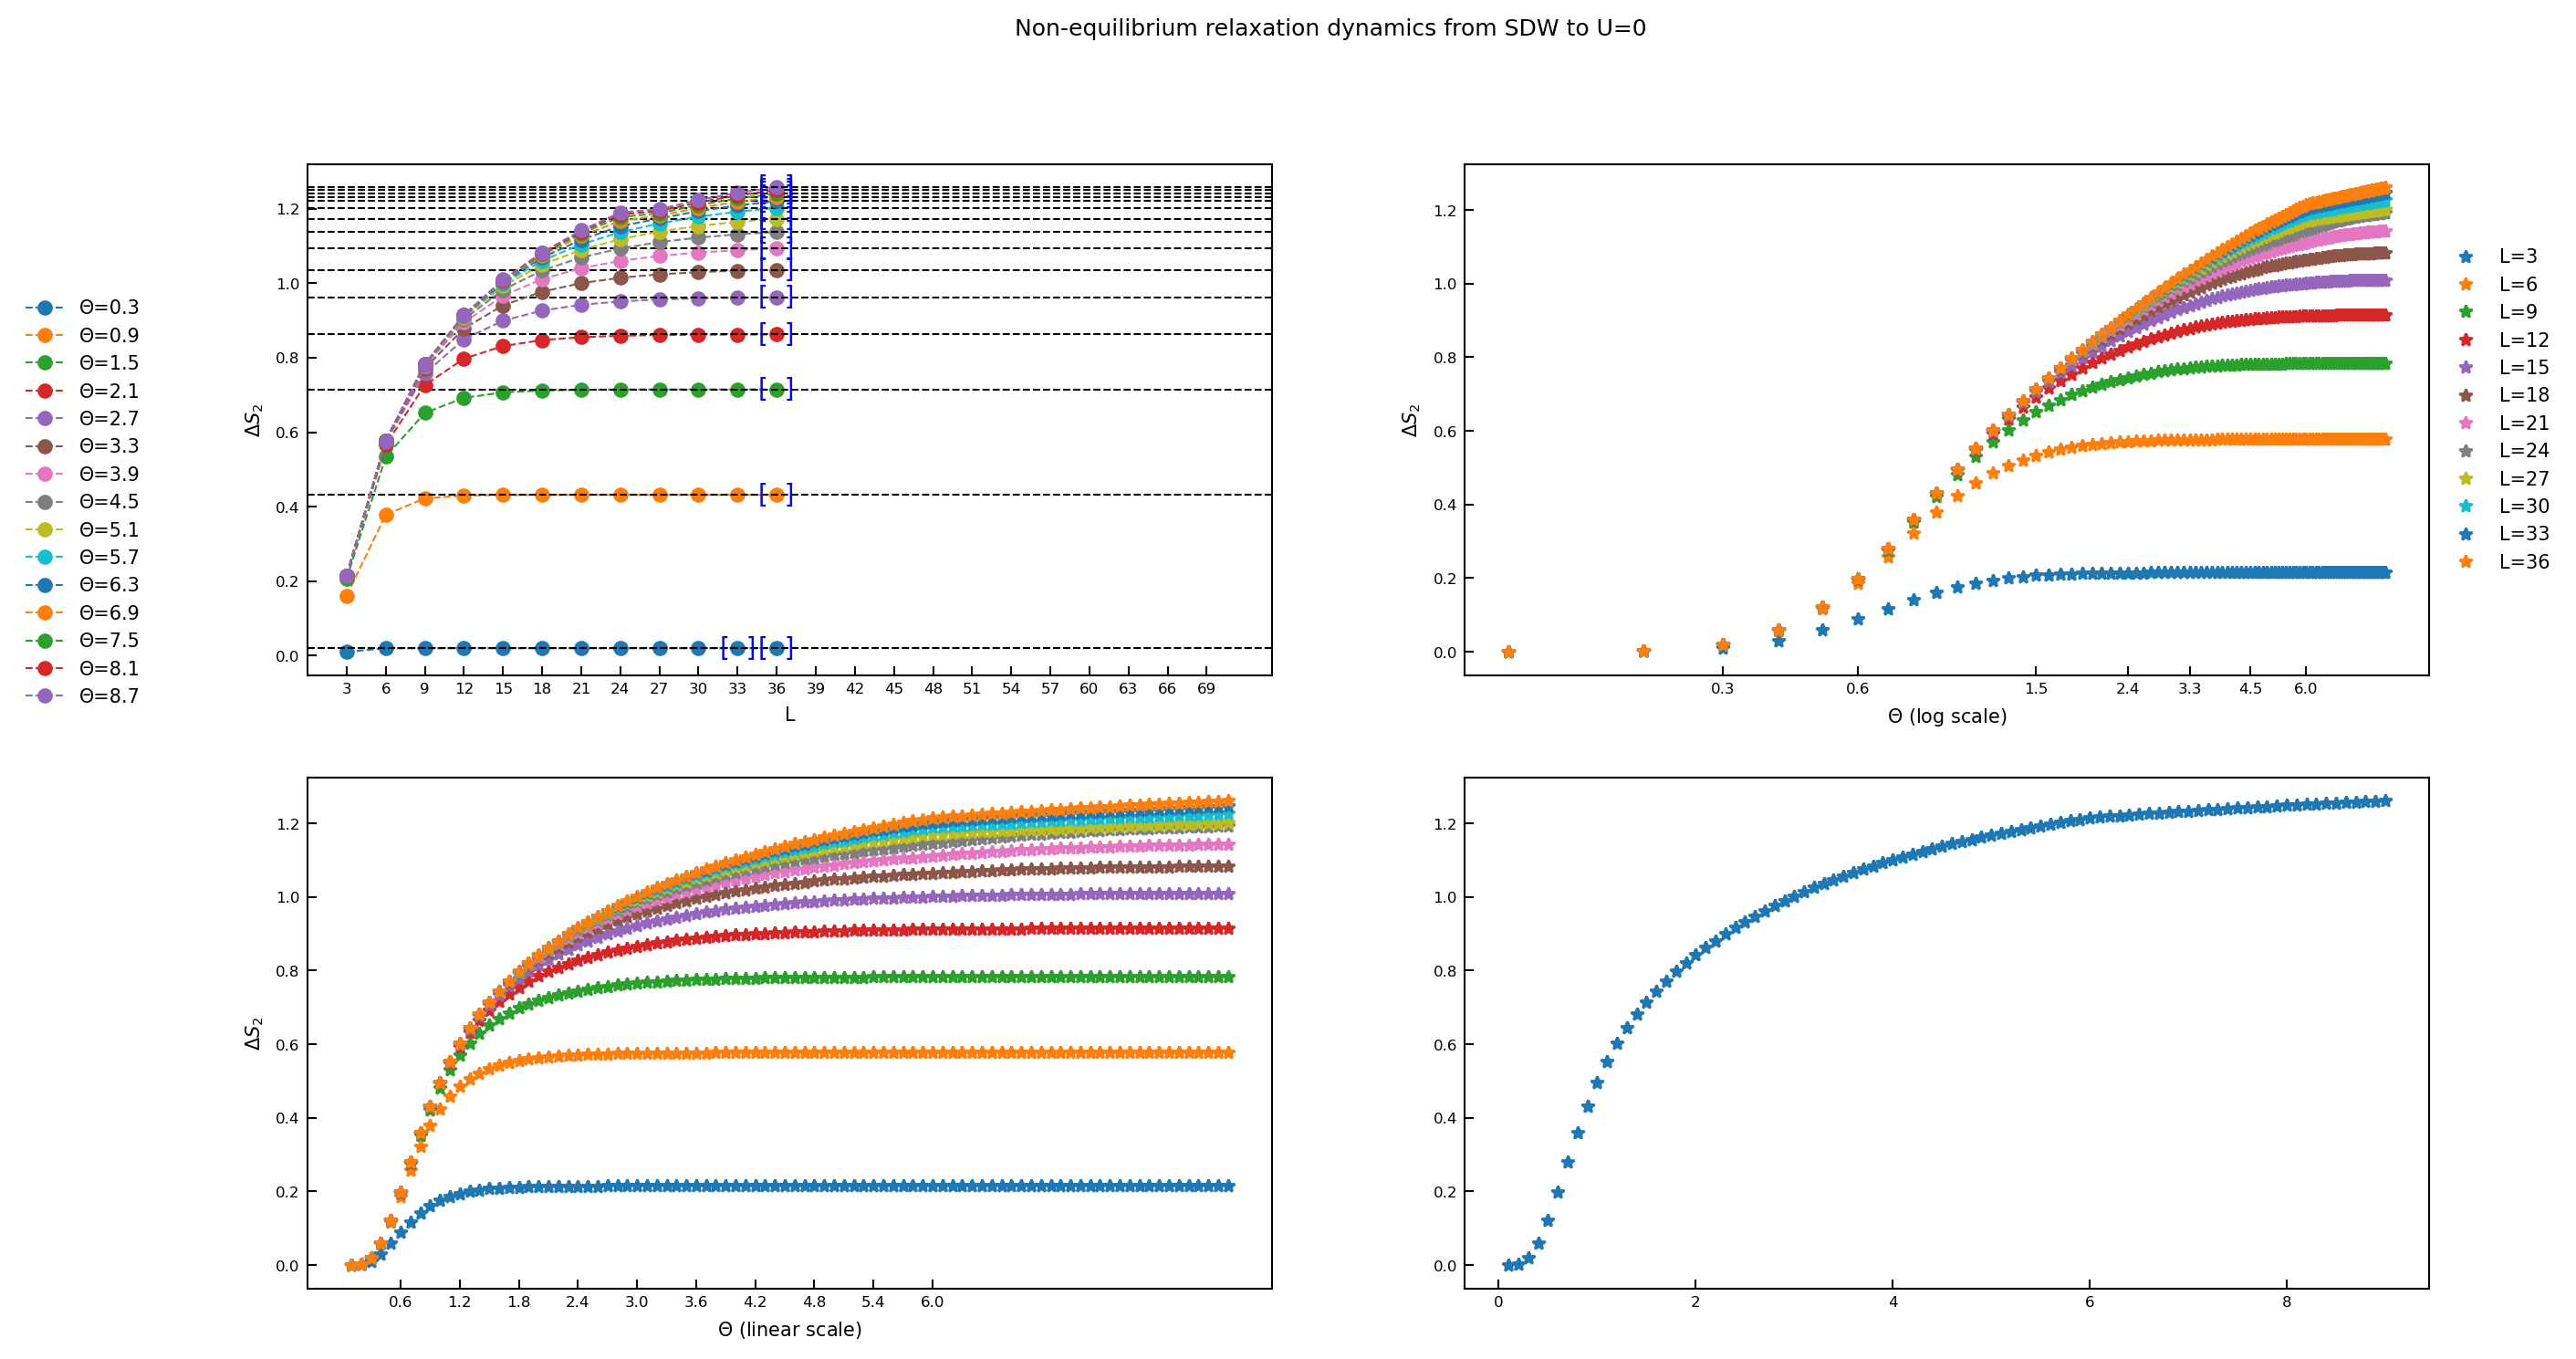

In [4]:
fig, axs = plt.subplots(2, 2, figsize=(15,8), dpi=200)

fig.suptitle(f"Non-equilibrium relaxation dynamics from SDW to U=0 ")
xxxx=np.round(np.arange(0.6,6.2,0.6),1)
xxx=[0.3,0.6,1.5,2.4,3.3,4.5,6.0]
plt.subplot(2,2,1)

Avg=[]
Lmin=[]
for i, (idx, col) in enumerate(dataSC.items()):
    
    # print(i, idx)
    
    data=[(col.index[i],col.values[i],0) for i in range(len(col.values))]
    index=unit_neardata(data)
    Lmin.append(col.index[index[0]])
    avg = np.mean(col.values[index])
    Avg.append(avg)
    if i%6==2:
        col.plot(linestyle='--',marker='o', markersize=5,label=f'Θ={idx}')
        for iii in index:
            plt.text(col.index[iii].astype(float),col.values[iii], "[  ]", color='blue',ha='center',va='center',fontsize=10)
            plt.axhline(avg, color="black", linestyle='--')
    # plt.text(2, avg, f'{avg:.2f}', ha='center', va='bottom')

plt.xlabel('L')
plt.ylabel(r'$\Delta S_2$')

plt.xticks(np.arange(3,LMAX,3),np.arange(3,LMAX,3))
plt.xlim(0,LMAX+2)
plt.legend(ncol=1,bbox_to_anchor=(-0.3, 0.75), loc='upper left', borderaxespad=0.)


# --------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

plt.subplot(2,2,2)

for i, (idx, row) in enumerate(dataSC.iterrows()):
    plt.plot(row.index.values.astype(float),row.values,linestyle='',marker='*', markersize=5,label=f'L={int(idx)}')
plt.xscale("log")
plt.xlabel(r"$ \Theta$ (log scale)")
plt.ylabel(r'$\Delta S_2$')
plt.xticks(xxx,xxx)
plt.minorticks_off()
plt.legend(ncol=1,bbox_to_anchor=(1.01, 0.85), loc='upper left', borderaxespad=0.)

# --------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
plt.subplot(2,2,3)

for i, (idx, row) in enumerate(dataSC.iterrows()):
    plt.plot(row.index.values.astype(float),row.values,linestyle='',marker='*', markersize=5,label=f'L={int(idx)}')
plt.xscale("linear")
plt.xlabel(r"$ \Theta$ (linear scale)")
plt.ylabel(r'$\Delta S_2$')

plt.xticks(xxxx,xxxx)

# --------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

plt.subplot(2,2,4)

tlist=dataSC.columns.values.astype(float)
plt.plot(tlist,Avg,linestyle='',marker='*', markersize=5, label=r"neq corner Entangle Entropy")

para,ds=linear_fit(np.log(tlist[xidx1:-4]),Avg[xidx1:-4])
x=np.linspace(tlist[xidx1-3],tlist[-1],100)
y=para[0]*np.log(x)+para[1]
plt.plot(x,y,label=f'$ y= {para[0]:.3f} \ln \Theta + {para[1]:.3f}$')

sss=para[0]

plt.xscale("log")
plt.xlabel(r"$ \Theta$ (log scale)")
plt.ylabel(r"$\Delta S_2$")
plt.xticks(xxx,xxx)
plt.minorticks_off()
plt.legend()


# --------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

# plt.tight_layout()

labels = 'abcd'

for ax, lbl in zip(axs.flat, labels):
    # 在左上角内侧放置字母，稍微向右下偏移半个字高/宽
    ax.annotate(lbl.upper(), xy=(0, 1), xycoords='axes fraction',
                xytext=(+0.5, 1.5), textcoords='offset fontsize',
                fontsize='medium', fontfamily='serif', fontweight='bold',
                va='top', ha='left', color='black')


# plt.savefig(os.path.join(path, f"SC_neqSDW_U=0.png"))
plt.show()



Text(0, 0.5, '$\\Delta S_2$')

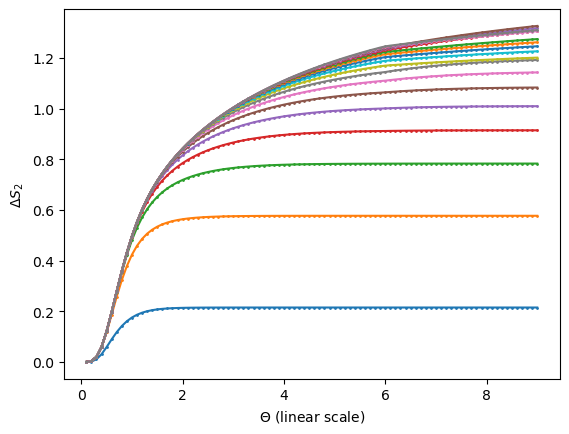

In [ ]:
for i, (idx, row) in enumerate(dataSC.iterrows()):
    plt.plot(row.index.values.astype(float),row.values,linestyle='-',marker='o', markersize=1,label=f'L={int(idx)}')
plt.xscale("linear")
plt.xlabel(r"$ \Theta$ (linear scale)")
plt.ylabel(r'$\Delta S_2$')

# plt.xticks(xxxx,xxxx)

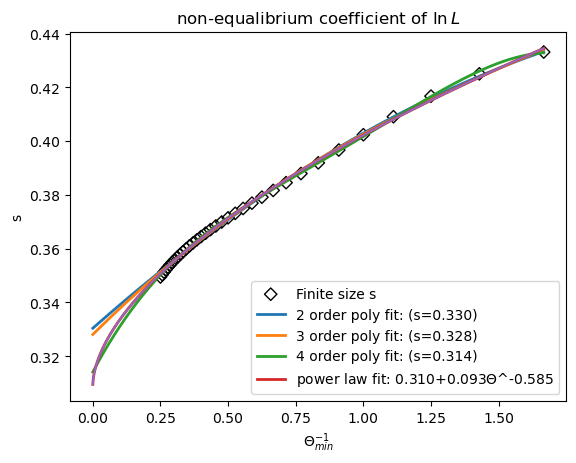

In [ ]:
def powerfit(x,y):
    initial_guess = [0.3, 1.0, 1.0]

    def model_func(x, a, b, c):
        return a + b * x**(c)
    
    params, _ = curve_fit(
        model_func, x, y,
        p0=initial_guess,
        # bounds=None,
        maxfev=100000
    )
    return params

def polyfit(x, y, n):
    A = np.ones((len(x), n+1))
    for i in range(1, n+1):
        A[:, i] = x**i
    coeffs, _, _, _ = np.linalg.lstsq(A, y, rcond=None)
    return coeffs

t_finite=[]
s_finite=[]
L_finite=[]
for xidx in range(5,len(Avg)-20):
    para=linear_fit(np.log(tlist[xidx:]),Avg[xidx:])
    s_finite.append(para[0])
    t_finite.append(tlist[xidx])
    L_finite.append(Lmin[xidx])
plt.scatter(1/np.array(t_finite),s_finite,marker='D',s=40,label="Finite size s", facecolors='none',edgecolors='black')



x_fit = np.linspace(0.000001, max(1/np.array(t_finite)), 1000)
for Nfit in range(2, 5):
    coeffs = np.polyfit(1/np.array(t_finite), s_finite, Nfit)
    y_fit = np.polyval(coeffs, x_fit)
    plt.plot(x_fit, y_fit, lw=2, 
             label=f"{Nfit} order poly fit: (s={coeffs[-1]:.3f})")

coeffs = powerfit(1/np.array(t_finite), s_finite)
y_fit=coeffs[0]+ coeffs[1]*x_fit**(coeffs[2])
plt.plot(x_fit, y_fit, lw=2, 
             label=f"power law fit: {coeffs[0]:.3f}+{coeffs[1]:.3f}$\Theta$^{-coeffs[2]:.3f}")
plt.plot(x_fit,y_fit)

# plt.ylim(0.22,0.4)
# plt.xlim(0, max(1/np.array(t_finite))+0.05)
plt.xlabel(r"$\Theta_{min}^{-1}$")
plt.ylabel("s")
plt.title(r"non-equalibrium coefficient of $\ln L$")
plt.legend()
plt.savefig(os.path.join(path, f"SCneq_para.png"))


plt.show()

In [ ]:
idx=3

dataSC.iloc[1]

0.1    0.000082
0.2    0.003217
0.3    0.019782
0.4    0.058128
0.5    0.116644
0.6    0.186604
0.7    0.257961
0.8    0.323255
0.9    0.378719
1      0.423558
1.1    0.458694
1.2    0.485741
1.3    0.506385
1.4    0.522108
1.5    0.534106
1.6    0.543301
1.7    0.550389
1.8    0.555886
1.9    0.560177
2      0.563546
2.1    0.566206
2.2    0.568316
2.3    0.569999
2.4    0.571345
2.5    0.572426
2.6    0.573297
2.7    0.574000
2.8    0.574569
2.9    0.575030
3      0.575404
3.1    0.575708
3.2    0.575956
3.3    0.576158
3.4    0.576322
3.5    0.576456
3.6    0.576566
3.7    0.576655
3.8    0.576728
3.9    0.576788
4      0.576837
4.1    0.576877
4.2    0.576910
4.3    0.576936
4.4    0.576958
4.5    0.576976
4.6    0.576991
4.7    0.577003
4.8    0.577012
4.9    0.577020
5      0.577027
5.1    0.577032
5.2    0.577037
5.3    0.577040
5.4    0.577043
5.5    0.577046
5.6    0.577047
5.7    0.577052
5.8    0.577052
5.9    0.577032
6      0.577069
Name: 6, dtype: float64

In [ ]:
dataSC.iloc[1].values-sss*np.log(idx)

array([-0.40204417, -0.39890883, -0.38234368, -0.34399806, -0.28548238,
       -0.21552225, -0.14416506, -0.07887067, -0.02340675,  0.02143157,
        0.0565682 ,  0.0836153 ,  0.1042593 ,  0.1199821 ,  0.13197985,
        0.14117521,  0.14826294,  0.15376024,  0.1580508 ,  0.16141967,
        0.16407958,  0.16619032,  0.16787277,  0.16921912,  0.1703002 ,
        0.17117083,  0.17187376,  0.17244252,  0.17290357,  0.17327788,
        0.17358219,  0.17382985,  0.1740316 ,  0.17419608,  0.17433027,
        0.1744398 ,  0.17452925,  0.17460234,  0.17466206,  0.17471089,
        0.17475081,  0.17478346,  0.17481017,  0.17483202,  0.1748499 ,
        0.17486453,  0.1748765 ,  0.17488629,  0.17489432,  0.17490088,
        0.17490629,  0.17491069,  0.1749144 ,  0.17491725,  0.17491978,
        0.17492055,  0.17492559,  0.17492574,  0.17490585,  0.17494291])

3 Index(['0.1', '0.2', '0.3', '0.4', '0.5', '0.6', '0.7', '0.8', '0.9', '1',
       '1.1', '1.2', '1.3', '1.4', '1.5', '1.6', '1.7', '1.8', '1.9', '2',
       '2.1', '2.2', '2.3', '2.4', '2.5', '2.6', '2.7', '2.8', '2.9', '3',
       '3.1', '3.2', '3.3', '3.4', '3.5', '3.6', '3.7', '3.8', '3.9', '4',
       '4.1', '4.2', '4.3', '4.4', '4.5', '4.6', '4.7', '4.8', '4.9', '5',
       '5.1', '5.2', '5.3', '5.4', '5.5', '5.6', '5.7', '5.8', '5.9', '6'],
      dtype='object')
6 Index(['0.1', '0.2', '0.3', '0.4', '0.5', '0.6', '0.7', '0.8', '0.9', '1',
       '1.1', '1.2', '1.3', '1.4', '1.5', '1.6', '1.7', '1.8', '1.9', '2',
       '2.1', '2.2', '2.3', '2.4', '2.5', '2.6', '2.7', '2.8', '2.9', '3',
       '3.1', '3.2', '3.3', '3.4', '3.5', '3.6', '3.7', '3.8', '3.9', '4',
       '4.1', '4.2', '4.3', '4.4', '4.5', '4.6', '4.7', '4.8', '4.9', '5',
       '5.1', '5.2', '5.3', '5.4', '5.5', '5.6', '5.7', '5.8', '5.9', '6'],
      dtype='object')
9 Index(['0.1', '0.2', '0.3', '0.4', '0.5', '0.6',

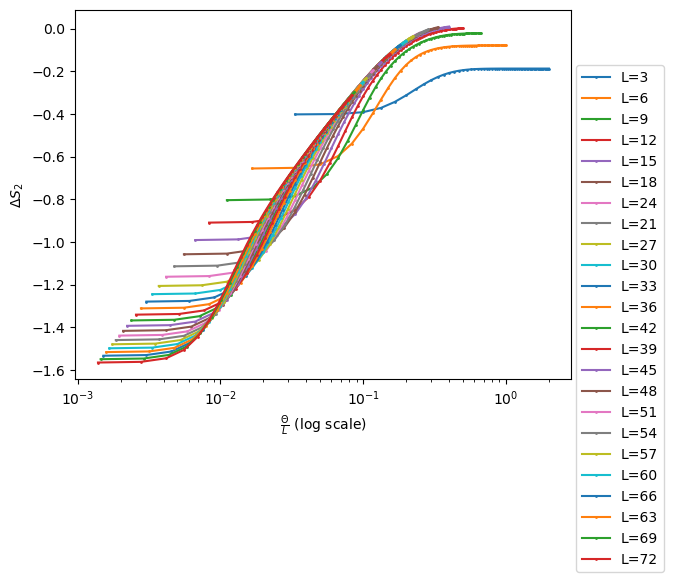

In [ ]:
for i, (idx, row) in enumerate(dataSC.iterrows()):
    print(idx,row.index)
    plt.plot(row.index.values.astype(float)/idx,row.values-sss*np.log(idx),linestyle='-',marker='o', markersize=1,label=f'L={int(idx)}')
plt.xscale("log")
plt.xlabel(r"$ \frac{\Theta}{L}$ (log scale)")
plt.ylabel(r'$\Delta S_2$')
# plt.xticks(xxxx,xxxx)
plt.legend(ncol=1,bbox_to_anchor=(1.01, 0.85), loc='upper left', borderaxespad=0.)
plt.show()

----------------------

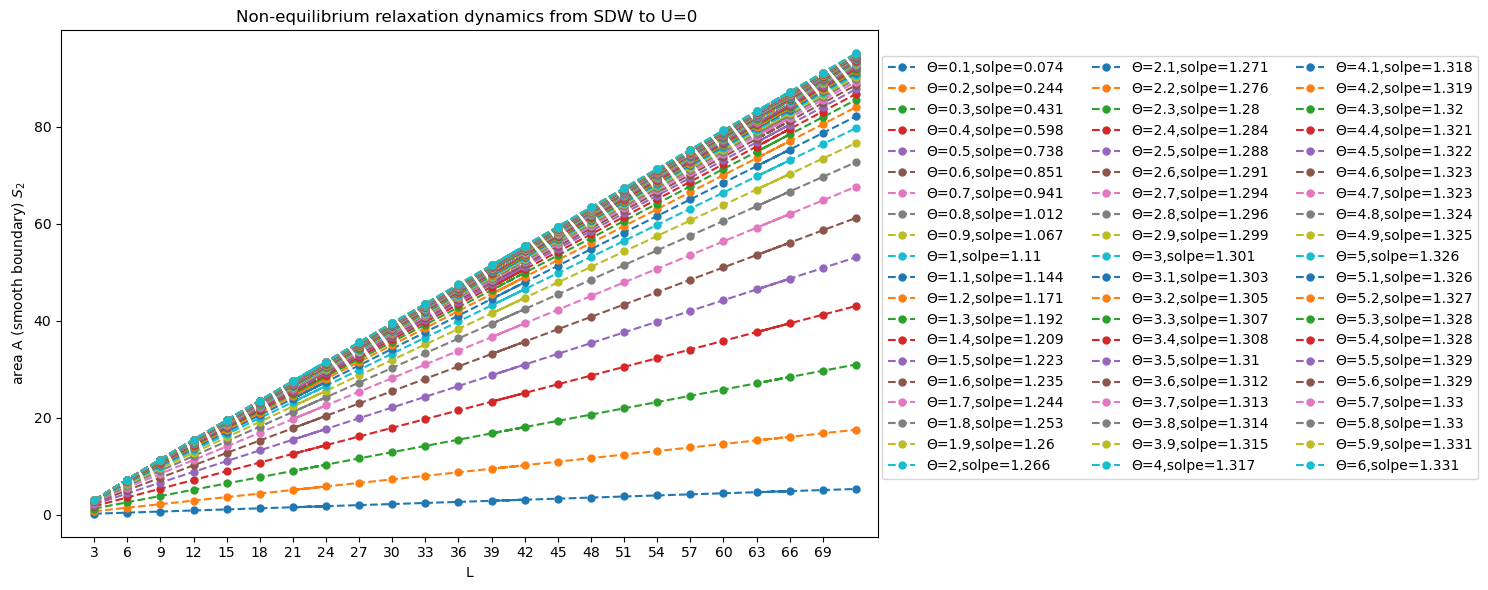

In [ ]:
# Fix Theta

Slope=[]

plt.figure(figsize=(15,6))
plt.title((f"Non-equilibrium relaxation dynamics from SDW to U=0 "))

for i, (idx, col) in enumerate(dataA.items()):
    # print(i, idx)
    

    Slope.append(np.polyfit(col.index, col.values, 1)[0] )

    col.plot(linestyle='--',marker='o', markersize=5,label=f'Θ={idx},solpe={np.round(Slope[-1],3)}')

    # data=[(,,0) for i in range(len(col.values))]
    # index=unit_neardata(data)
    # avg = np.mean(col.values[index])
    # Avg.append(avg)
    # plt.axhline(avg, color="black", linestyle='--')
    # plt.text(2, avg, f'{avg:.2f}', ha='center', va='bottom')

plt.xlabel('L')
plt.ylabel(r'area A (smooth boundary) $S_2$')
plt.xticks(np.arange(3,LMAX,3),np.arange(3,LMAX,3))
plt.xlim(0,LMAX+2)
plt.legend(ncol=3,bbox_to_anchor=(1.005, 0.95), loc='upper left', borderaxespad=0.)

plt.tight_layout()
plt.savefig(os.path.join(path, f"Half_fixTheta.png"))
plt.show()

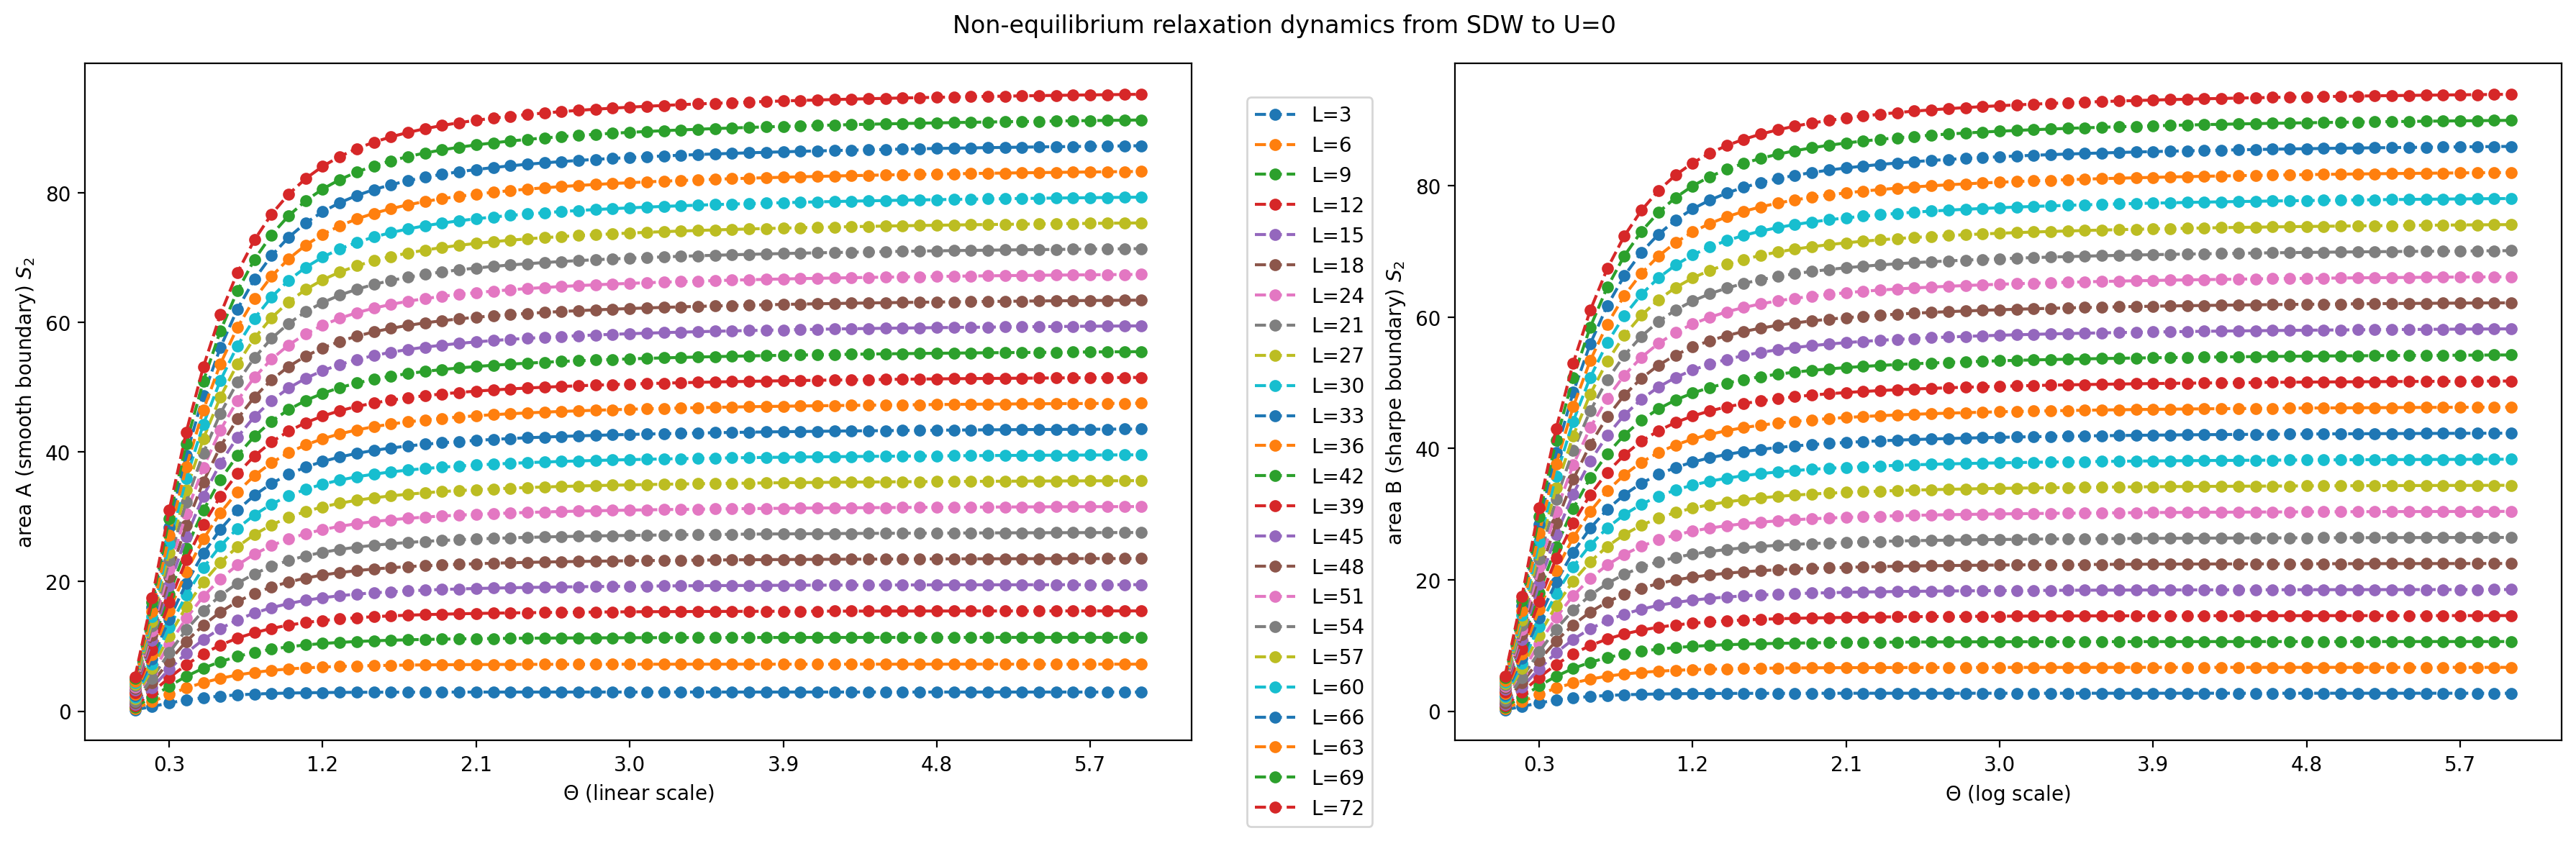

In [ ]:
fig=plt.figure(figsize=(18,6), dpi=200)
fig.suptitle(f"Non-equilibrium relaxation dynamics from SDW to U=0 ")

plt.subplot(1,2,1)

for i, (idx, row) in enumerate(dataA.iterrows()):
    plt.plot(row.index.values.astype(float),row.values,linestyle='--',marker='o', markersize=5,label=f'L={int(idx)}')
plt.xscale("linear")
plt.xlabel(r"$ \Theta$ (linear scale)")
plt.ylabel(r'area A (smooth boundary) $S_2$')
xxxx=np.round(np.arange(0.3,6,0.9),1)
plt.xticks(xxxx,xxxx)
plt.legend(bbox_to_anchor=(1.05, 0.95), loc='upper left', borderaxespad=0.)

# --------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

plt.subplot(1,2,2)

for i, (idx, row) in enumerate(dataB.iterrows()):
    plt.plot(row.index.values.astype(float),row.values,linestyle='--',marker='o', markersize=5,label=f'L={int(idx)}')
# plt.xscale("log")
plt.xlabel(r"$ \Theta$ (log scale)")
plt.ylabel(r'area B (sharpe boundary) $S_2$')
xxxx=np.round(np.arange(0.3,6,0.9),1)
plt.xticks(xxxx,xxxx)
# plt.legend(bbox_to_anchor=(0.05, 0.95), loc='upper left', borderaxespad=0.)


plt.tight_layout()
plt.savefig(os.path.join(path, f"Half_neqSDW_U=0.png"))
plt.show()

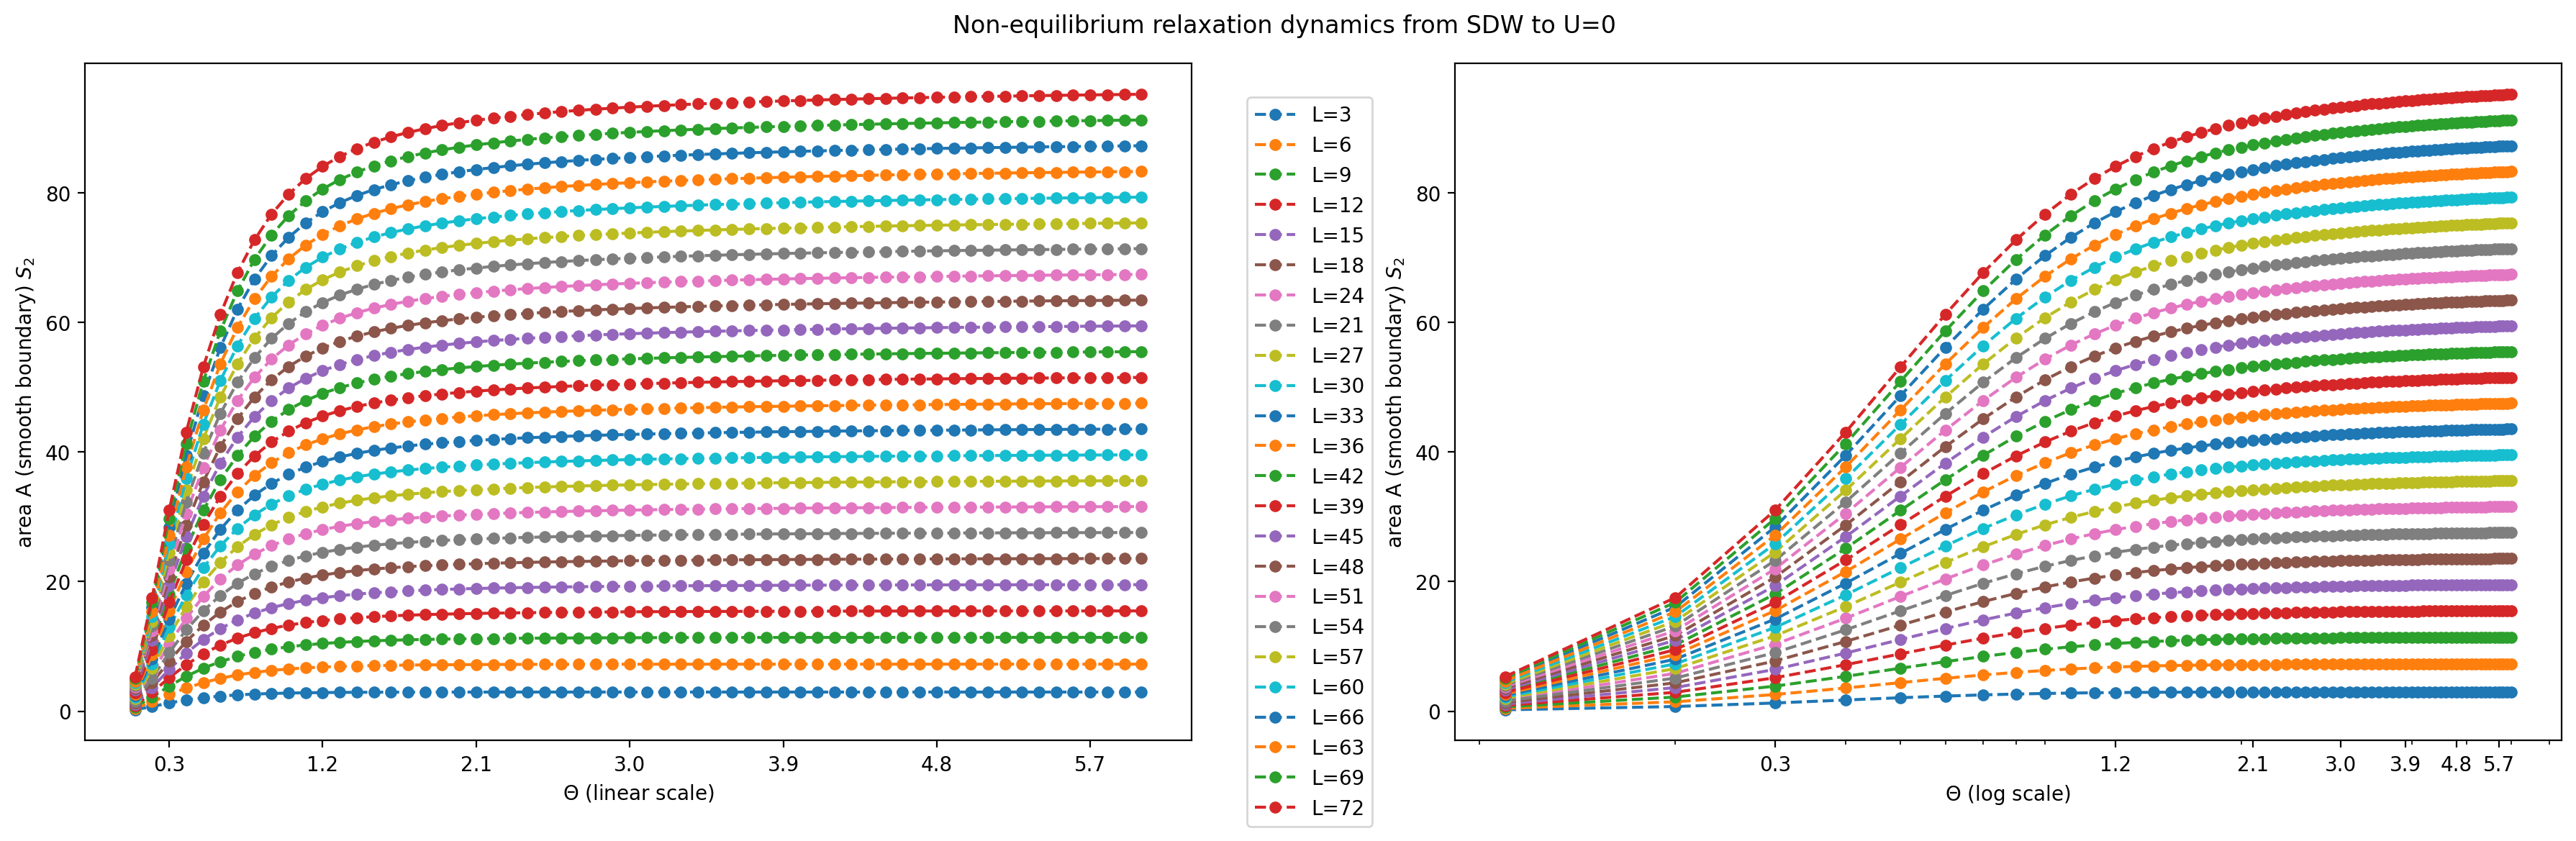

In [ ]:
fig=plt.figure(figsize=(18,6), dpi=200)
fig.suptitle(f"Non-equilibrium relaxation dynamics from SDW to U=0 ")

plt.subplot(1,2,1)

for i, (idx, row) in enumerate(dataA.iterrows()):
    plt.plot(row.index.values.astype(float),row.values,linestyle='--',marker='o', markersize=5,label=f'L={int(idx)}')
plt.xscale("linear")
plt.xlabel(r"$ \Theta$ (linear scale)")
plt.ylabel(r'area A (smooth boundary) $S_2$')
xxxx=np.round(np.arange(0.3,6,0.9),1)
plt.xticks(xxxx,xxxx)
plt.legend(bbox_to_anchor=(1.05, 0.95), loc='upper left', borderaxespad=0.)

# --------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

plt.subplot(1,2,2)

for i, (idx, row) in enumerate(dataA.iterrows()):
    plt.plot(row.index.values.astype(float),row.values,linestyle='--',marker='o', markersize=5,label=f'L={int(idx)}')
plt.xscale("log")
plt.xlabel(r"$ \Theta$ (log scale)")
plt.ylabel(r'area A (smooth boundary) $S_2$')
xxxx=np.round(np.arange(0.3,6,0.9),1)
plt.xticks(xxxx,xxxx)
# plt.legend(bbox_to_anchor=(0.05, 0.95), loc='upper left', borderaxespad=0.)


plt.tight_layout()
plt.savefig(os.path.join(path, f"Half_neqSDW_U=0.png"))
plt.show()

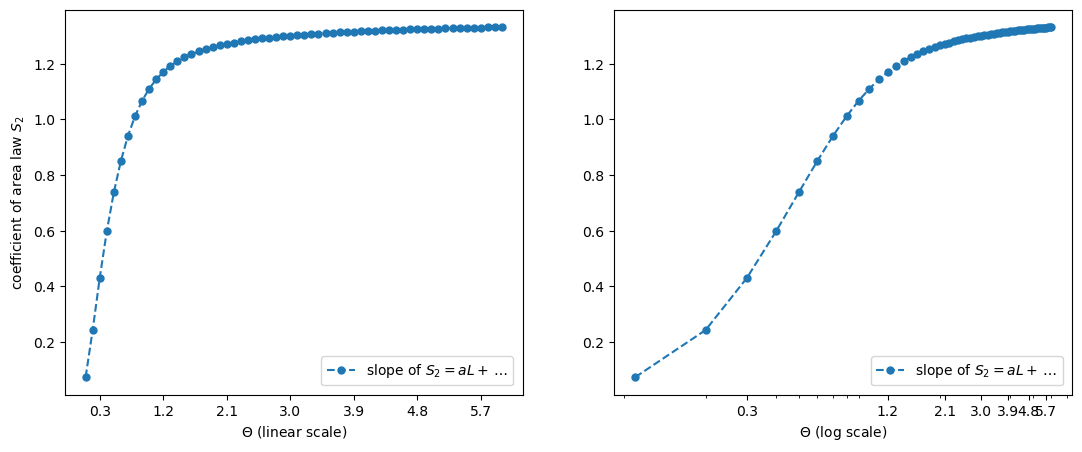

In [ ]:
plt.figure(figsize=(13,5))

plt.subplot(1,2,1)

tlist=dataB.columns.values.astype(float)
plt.plot(tlist,Slope,linestyle='--',marker='o', markersize=5, label=r"slope of $S_2=aL+\dots$")
plt.legend(bbox_to_anchor=(0.56, 0.1), loc='upper left', borderaxespad=0.)
plt.xlabel(r'$\Theta$ (linear scale)')
plt.ylabel(r'coefficient of area law $S_2$')
plt.xticks(xxxx,xxxx)


plt.subplot(1,2,2)

tlist=dataB.columns.values.astype(float)
plt.plot(tlist,Slope,linestyle='--',marker='o', markersize=5, label=r"slope of $S_2=aL+\dots$")
plt.legend(bbox_to_anchor=(0.56, 0.1), loc='upper left', borderaxespad=0.)
plt.xscale("log")
plt.xlabel(r'$\Theta$ (log scale)')
plt.xticks(xxxx,xxxx)



plt.savefig(os.path.join(path, f"Half_slope.png"))
plt.show()